## Depth to groundwater data cleaning

Well location, measurement date, depth-to-water or groundwater elevation

Charlsey Tomassetti


### 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from pathlib import Path

In [3]:
depth = pd.read_csv("depth_groundwater.csv")

depth_gdf = gpd.GeoDataFrame(
    depth,
    geometry=gpd.points_from_xy(
        depth["longitude"],
        depth["latitude"]
    ),
    crs="EPSG:4326"
)

In [10]:
#load clean groundwater data
groundwater = pd.read_csv("../../groundwater_nitrate_clean.csv")

groundwater_gdf = gpd.GeoDataFrame(
    groundwater,
    geometry=gpd.points_from_xy(
        groundwater["gm_longitude"],
        groundwater["gm_latitude"]
    ),
    crs="EPSG:4326"
)

In [4]:
# Load HUC8 watershed boundary
gdb = Path("..") / ("..") / ("NHD_H_18060005_HU8_GDB") / "NHD_H_18060005_HU8_GDB.gdb"

huc8 = gpd.read_file(
    gdb,
    layer="WBDHU8"
)

huc8.head()

,tnmid,metasourceid,sourcedatadesc,sourceoriginator,sourcefeatureid,loaddate,referencegnis_ids,areaacres,areasqkm,states,huc8,name,shape_Length,shape_Area,geometry
0,{2EB2E16D-AA63-432F-9DC1-1820721507ED},None,None,None,None,2012-06-11 07:54:57+00:00,None,2130628.5,8622.36,CA,18060005,Salinas,7.476846,0.862215,"MULTIPOLYGON (((-121.79903 36.74909, -121.7986..."


In [6]:
huc8 = huc8.to_crs(depth_gdf.crs)

In [7]:
#clipping points to watershed boundary
depth_huc8 = gpd.clip(
    depth_gdf,
    huc8
)

In [8]:
#verify that clipping was successful
print("Original groundwater depth records:", len(depth_gdf))
print("Records inside HUC8:", len(depth_huc8))

depth_huc8.head()

Original groundwater depth records: 47646
Records inside HUC8: 240


,site_code,stn_id,swn,well_name,continuous_data_station_number,latitude,longitude,gse,rpe,gse_method,gse_acc,basin_code,basin_name,county_name,well_depth,well_use,well_type,wcr_no,monitoring_program,geometry
20299,355262N1205215W001,50535,28S13E01B001M,PASO-0066,NaN,35.52622,-120.52150,1099.93,1099.93,GPS,Unknown,3-004.06,Paso Robles Area,San Luis Obispo,254.0,Residential,Single Well,NaN,SGMA Representative,POINT (-120.5215 35.52622)
20583,355700N1205448W004,61662,27S13E23C004M,SLOGSA-01 Lower,27S13E23C004M,35.57005,-120.54480,1011.18,1013.90,Surveyed to a benchmark,0.1 ft.,3-004.06,Paso Robles Area,San Luis Obispo,595.0,Observation,Part of a nested/multi-completion well,WCR2025-003447,VOLUNTARY,POINT (-120.5448 35.57005)
20582,355700N1205448W003,61661,27S13E23C003M,SLOGSA-01 Middle,27S13E23C003M,35.57006,-120.54480,1011.18,1014.04,Surveyed to a benchmark,0.1 ft.,3-004.06,Paso Robles Area,San Luis Obispo,295.0,Observation,Part of a nested/multi-completion well,WCR2025-003447,VOLUNTARY,POINT (-120.5448 35.57006)
20581,355700N1205448W002,61660,27S13E23C002M,SLOGSA-01 Upper,27S13E23C002M,35.57008,-120.54482,1011.51,1013.85,Surveyed to a benchmark,0.1 ft.,3-004.06,Paso Robles Area,San Luis Obispo,115.0,Observation,Single Well,WCR2025-003449,VOLUNTARY,POINT (-120.54482 35.57008)
20580,355700N1205448W001,61659,27S13E23C001M,SLOGSA-01 Shallow,27S13E23C001M,35.57010,-120.54482,1011.70,1014.15,Surveyed to a benchmark,0.1 ft.,3-004.06,Paso Robles Area,San Luis Obispo,65.0,Observation,Single Well,WCR2025-003448,VOLUNTARY,POINT (-120.54482 35.5701)


In [ ]:
depth_huc8["county_name"].value_counts()

county_name
Monterey           188
San Luis Obispo     51
Merced               1
Name: count, dtype: int64

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

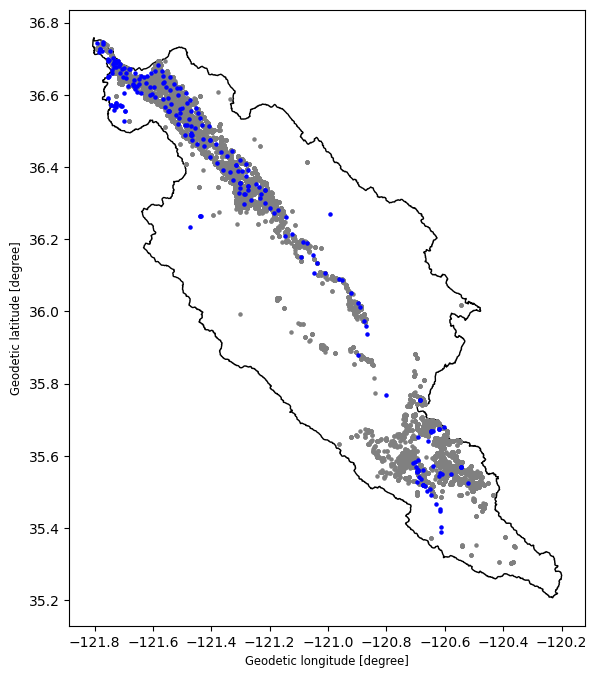

In [11]:
#verify that clipping was successful

ax = huc8.plot(
    figsize=(10, 8),
    facecolor="none",
    edgecolor="black"
)

groundwater_gdf.plot(
    ax=ax,
    color="grey",
    markersize=5
)

depth_huc8.plot(
    ax=ax,
    color="blue",
    markersize=5
)


In [ ]:
depth_huc8.columns

Index(['site_code', 'stn_id', 'swn', 'well_name',
       'continuous_data_station_number', 'latitude', 'longitude', 'gse', 'rpe',
       'gse_method', 'gse_acc', 'basin_code', 'basin_name', 'county_name',
       'well_depth', 'well_use', 'well_type', 'wcr_no', 'monitoring_program',
       'geometry'],
      dtype='str')

In [16]:
depth_huc8.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 240 entries, 20299 to 31790
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   site_code                       240 non-null    str     
 1   stn_id                          240 non-null    int64   
 2   swn                             206 non-null    str     
 3   well_name                       240 non-null    str     
 4   continuous_data_station_number  7 non-null      str     
 5   latitude                        240 non-null    float64 
 6   longitude                       240 non-null    float64 
 7   gse                             240 non-null    float64 
 8   rpe                             240 non-null    float64 
 9   gse_method                      240 non-null    str     
 10  gse_acc                         240 non-null    str     
 11  basin_code                      233 non-null    str     
 12  basin_name   

https://data.cnra.ca.gov/dataset/periodic-groundwater-level-measurements/resource/af157380-fb42-4abf-b72a-6f9f98868077

| Column  | Description |
|:--------:|:--------:|
|  gse   |  Ground surface elevation (feet, NAVD88)   |  Row 1   |
|  rpe   |  Reference point elevation (feet, NAVD88)   |  
|  gse_method   |  Ground surface elevation measurement method   |  
|  well_depth  |  Well depth in feet below ground surface.  |  



In [17]:
depth_clean = depth_huc8.drop(columns=['site_code', 'stn_id', 'swn',
       'continuous_data_station_number', 'gse_acc', 'basin_code', 'basin_name',
       'wcr_no', 'monitoring_program'])

In [19]:
depth_clean.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 240 entries, 20299 to 31790
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   well_name    240 non-null    str     
 1   latitude     240 non-null    float64 
 2   longitude    240 non-null    float64 
 3   gse          240 non-null    float64 
 4   rpe          240 non-null    float64 
 5   gse_method   240 non-null    str     
 6   county_name  240 non-null    str     
 7   well_depth   221 non-null    float64 
 8   well_use     240 non-null    str     
 9   well_type    240 non-null    str     
 10  geometry     240 non-null    geometry
dtypes: float64(5), geometry(1), str(5)
memory usage: 36.2 KB


In [20]:
depth_clean.to_csv("groundwater_depth_clean.csv")